In [40]:
import numpy as np 
import matplotlib.pyplot as plt

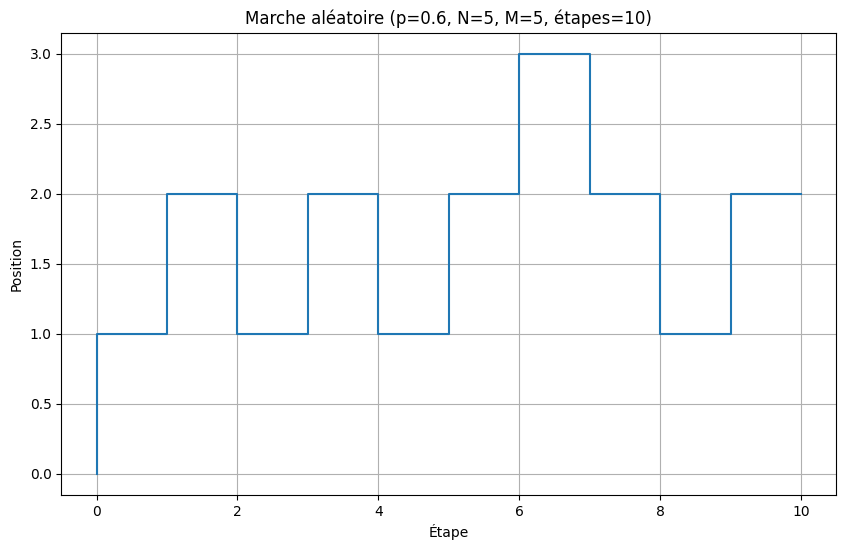

In [41]:

def simulate_random_walk(p, N, M, steps):
  
    position = 0
    positions = [position]
    
    for _ in range(steps):
        if np.random.rand() < p:
            # Aller à droite
            if position < M:
                position += 1
        else:
            # Aller à gauche
            if position > -N:
                position -= 1
        positions.append(position)
    
    return positions

p = 0.6  # Probabilité d'aller à droite
N = 5    # Borne inférieure -N
M = 5    # Borne supérieure M
steps = 10 # Nombre d'étapes

positions = simulate_random_walk(p, N, M, steps)

# Tracer la position en fonction du temps
plt.figure(figsize=(10, 6))
plt.step(range(len(positions)), positions)
plt.title(f'Marche aléatoire (p={p}, N={N}, M={M}, étapes={steps})')
plt.xlabel('Étape')
plt.ylabel('Position')
plt.grid(True)
plt.show()

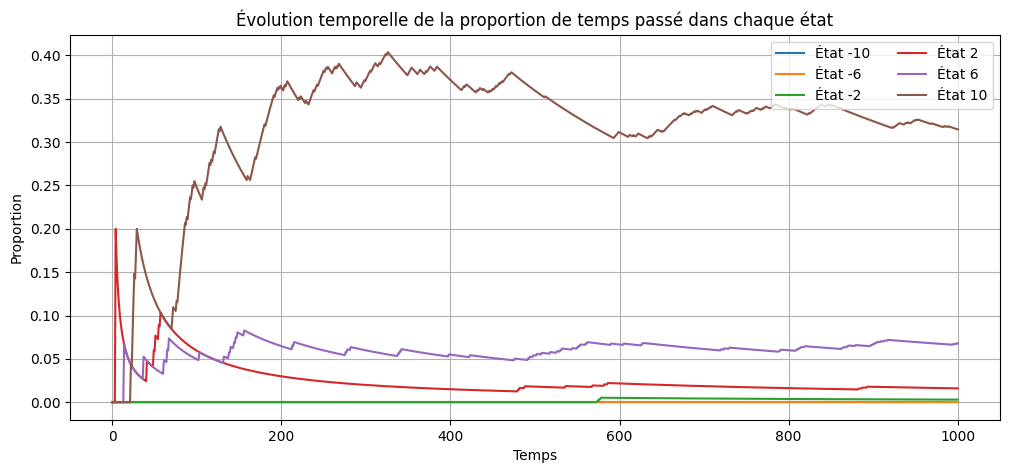

In [42]:



# --- Paramètres ---
p = 0.6       # Probabilité d'aller à droite
N = 10        # Borne gauche (-10)
M = 10        # Borne droite (+10)
steps = 1000  # Nombre de pas

# Simulation
trajectoire = simulate_random_walk(p, N, M, steps)


# --- 4. Calcul de l'évolution de la proportion de temps passé ---
def calculate_time_proportions(trajectoire, N, M):
    etats = np.arange(-N, M + 1)
    nb_etats = len(etats)
    steps = len(trajectoire)
    
    # Matrice pour stocker l'évolution des proportions
    # Lignes = Temps, Colonnes = Proportion pour chaque état
    proportions_history = np.zeros((steps, nb_etats))
    counts = np.zeros(nb_etats)
    
    for t in range(steps):
        # On trouve l'index de l'état (ex: si pos=-N, index=0)
        pos_actuelle = trajectoire[t]
        index = pos_actuelle + N
        counts[index] += 1
        
        # Calcul de la proportion à l'instant t
        proportions_history[t] = counts / (t + 1)
        
    return etats, proportions_history

etats, prop_history = calculate_time_proportions(trajectoire, N, M)

# Affichage de l'évolution des proportions pour quelques états clés
plt.figure(figsize=(12, 5))
for i in range(0, len(etats), 4): # On affiche un état sur 4 pour la clarté
    plt.plot(prop_history[:, i], label=f"État {etats[i]}")

plt.title("Évolution temporelle de la proportion de temps passé dans chaque état")
plt.xlabel("Temps")
plt.ylabel("Proportion")
plt.legend(loc='upper right', ncol=2)
plt.grid(True)
plt.show()

In [43]:
def stationnary_markov(p,n,esilon):

    x=np.zeros(n)
    k=0
    while True:
        x[k]=x[k-1]*p
        k+=1
        if np.norm(xk+1-xk)<epslon:
            break
    for i in rnage(0,n+2):

         j+=x[k]
        

Convergence atteinte en 585 itérations.


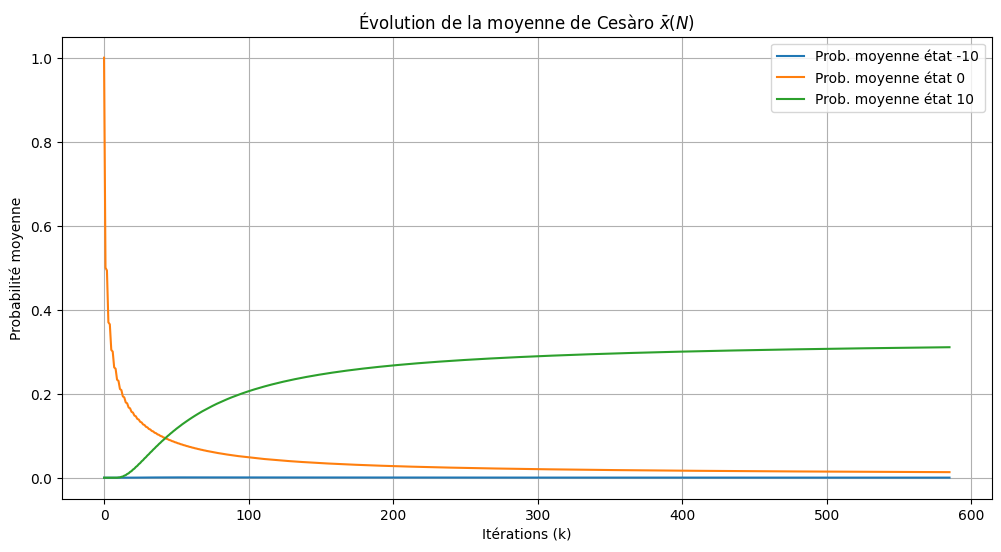

In [45]:
import numpy as np
import matplotlib.pyplot as plt

# --- Paramètres ---
p = 0.6
N = 10
M = 10
epsilon = 1e-8
etats = np.arange(-N, M + 1)
S = len(etats)

# --- 1. Construction de la Matrice de Transition P ---
P = np.zeros((S, S))

for i in range(S):
    if i == 0: # Bord gauche (-N)
        P[i, i+1] = p
        P[i, i] = 1 - p  # On reste sur place au lieu de sortir
    elif i == S - 1: # Bord droit (M)
        P[i, i-1] = 1 - p
        P[i, i] = p      # On reste sur place au lieu de sortir
    else: # États centraux
        P[i, i+1] = p
        P[i, i-1] = 1 - p

# --- 2. Algorithme Power Method ---
x_k = np.zeros(S)
x_k[N] = 1.0 # État initial : on part de 0 (qui est à l'index N)

x_history = [x_k.copy()]
mean_x_history = [x_k.copy()]
sum_x = x_k.copy()

k = 1
while True:
    # x(k) = x(k-1) * P
    x_next = np.dot(x_k, P)
    
    # Calcul de la moyenne de Cesàro : x_bar(N)
    sum_x += x_next
    mean_x = sum_x / (k + 1)
    mean_x_history.append(mean_x.copy())
    
    # Condition d'arrêt : norme de la différence
    if np.linalg.norm(x_next - x_k) < epsilon:
        break
        
    x_k = x_next
    x_history.append(x_k.copy())
    k += 1

print(f"Convergence atteinte en {k} itérations.")

# --- 3. Graphique de l'évolution de x_bar(N) ---
plt.figure(figsize=(12, 6))
mean_x_history = np.array(mean_x_history)

# On affiche l'évolution de la probabilité moyenne pour quelques états
indices_a_afficher = [0, N, S-1] # Borne gauche, Milieu, Borne droite
for idx in indices_a_afficher:
    plt.plot(mean_x_history[:, idx], label=f"Prob. moyenne état {etats[idx]}")

plt.title("Évolution de la moyenne de Cesàro $\\bar{x}(N)$")
plt.xlabel("Itérations (k)")
plt.ylabel("Probabilité moyenne")
plt.legend()
plt.grid(True)
plt.show()

In [54]:
import numpy as np

# --- 1. Définition du Graphe (Matrice de Adjacence Normalisée A) ---
# On définit qui pointe vers qui. 
# Exemple : si le nœud 0 pointe vers 1 et 4, A[0,1] = 0.5 et A[0,4] = 0.5
nb_noeuds = 8 # 7 pages + Google.com (index 7)
A = np.zeros((nb_noeuds, nb_noeuds))

# Remplissez selon votre graphe (exemple arbitraire basé sur la figure) :
A[0, [1, 4]] = 0.5
A[1, 2] = 1.0
A[2, 5] = 1.0
A[3, [1, 2]] = 0.5
A[4, 5] = 1.0
A[5, 6] = 1.0
A[6, 7] = 1.0 # Le nœud 6 pointe vers Google
A[7, 0] = 1.0 # Google pointe vers le début (ou ailleurs)

# --- 2. Paramètres PageRank ---
alpha = 0.15
x_0 = np.zeros(nb_noeuds)
x_0[7] = 1.0  # La page d'accueil Google est l'index 7

# e est un vecteur de 1
e = np.ones(nb_noeuds)

# --- 3. Construction de la matrice Google A_alpha ---
# A_alpha = (1-alpha)*A + alpha * (e_transpose * x_0)
# Note : e.T * x_0 crée une matrice où chaque ligne est le vecteur x_0
teleport = np.outer(e, x_0)
A_alpha = (1 - alpha) * A + alpha * teleport

# --- 4. Power Method pour trouver le rang ---
x_k = x_0.copy()
epsilon = 1e-9

for i in range(100):
    x_next = np.dot(x_k, A_alpha)
    if np.linalg.norm(x_next - x_k) < epsilon:
        break
    x_k = x_next

# --- 5. Détermination du Rang ---
# Le rang est l'ordre décroissant des probabilités
print("Vecteur de probabilités final (Stationnaire) :\n", x_k)

ranking = np.argsort(x_k)[::-1] # Trie les indices du plus grand au plus petit
print("\nRang des pages (de la plus importante à la moins importante) :")
for rank, node_idx in enumerate(ranking):
    print(f"Position {rank + 1}: Nœud {node_idx} (Score: {x_k[node_idx]:.4f})")

Vecteur de probabilités final (Stationnaire) :
 [0.21625836 0.0919098  0.07812333 0.         0.0919098  0.14452816
 0.12284894 0.2544216 ]

Rang des pages (de la plus importante à la moins importante) :
Position 1: Nœud 7 (Score: 0.2544)
Position 2: Nœud 0 (Score: 0.2163)
Position 3: Nœud 5 (Score: 0.1445)
Position 4: Nœud 6 (Score: 0.1228)
Position 5: Nœud 4 (Score: 0.0919)
Position 6: Nœud 1 (Score: 0.0919)
Position 7: Nœud 2 (Score: 0.0781)
Position 8: Nœud 3 (Score: 0.0000)
